# Plot results from test_methods.py

The results are stored in a DataFrame with the following columns:
- method: Source reconstruction method
- region: Region onset of spike source
- half: EEG peak half rising time
- peak: EEG peak time

The following columns shows the correlation achieved by the method over multiple time points. <br>

## 📦 Imports

In [1]:
import pandas as pd
import seaborn as sns

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `corrs`: Source reconstruction correlations over time.

In [ ]:
results = pd.read_csv("test_methods.csv")
print(results.shape)
results.head(3)

(99000, 6)


,timepoint,correlation,method,region,half,peak
0,0.500,0.000000,cset,ctx-lh-precentral_1,False,False
1,0.504,0.025445,cset,ctx-lh-precentral_1,False,False
2,0.508,0.039083,cset,ctx-lh-precentral_1,False,False


#### ⚙️ **<font color=green>Plot correlation at half rising phase and peak phase</font>**

<Axes: xlabel='peak', ylabel='correlation'>

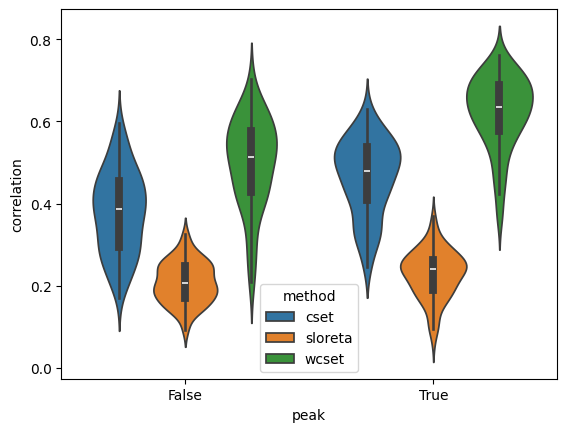

In [54]:
points = results[results["half"] | results["peak"]]
points = points.groupby(["method", "region", "half", "peak"]).mean()

sns.violinplot(data=points, x="peak", y="correlation", hue="method")

#### ⚙️ **<font color=green>Plot correlation over time</font>**

<Axes: xlabel='timepoint', ylabel='correlation'>

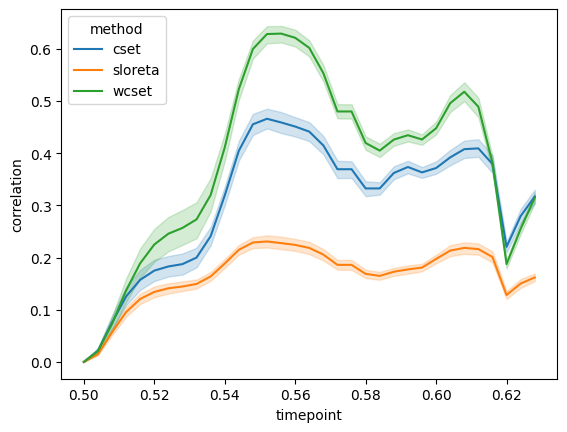

In [55]:
ts = results.drop(["half", "peak"], axis=1)
ts = ts.groupby(["method", "region", "timepoint"]).mean()

sns.lineplot(data=ts, x="timepoint", y="correlation", hue="method")

# Plot results from test_sabotage.py

The results are stored in a DataFrame with the following columns:
- subject: Template subject
- method: Source reconstruction method
- region: Region onset of spike source
- correlation: Correlation at peak time

## 📦 Imports

In [1]:
import pandas as pd
import seaborn as sns

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `sabotage`: Source reconstruction correlations for various degrees of connectome sabotaging

In [2]:
sabotage = pd.read_csv("sabotage.csv")
print(sabotage.shape)
sabotage.head(3)

(15000, 5)


,subject,method,location,correlation,sabotage
0,vepcon_sub-10,geometry,ctx-rh-precentral_14,0.365505,0.0
1,vepcon_sub-10,template,ctx-rh-precentral_14,0.330471,0.0
2,vepcon_sub-10,sloreta,ctx-rh-precentral_14,0.174292,0.0


<Axes: xlabel='method', ylabel='correlation'>

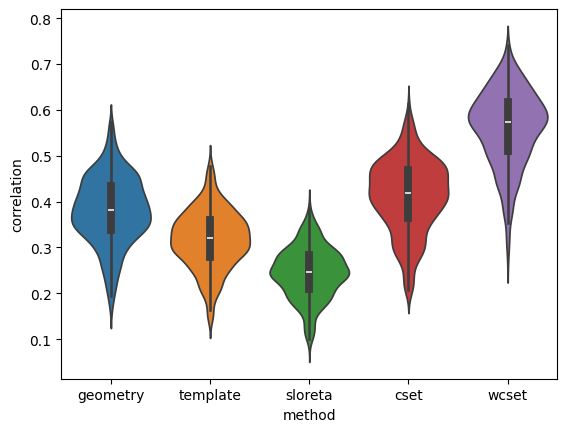

In [3]:
df = sabotage[sabotage["sabotage"]==0]
sns.violinplot(df, x="method", y="correlation", hue="method")

<Axes: xlabel='sabotage', ylabel='correlation'>

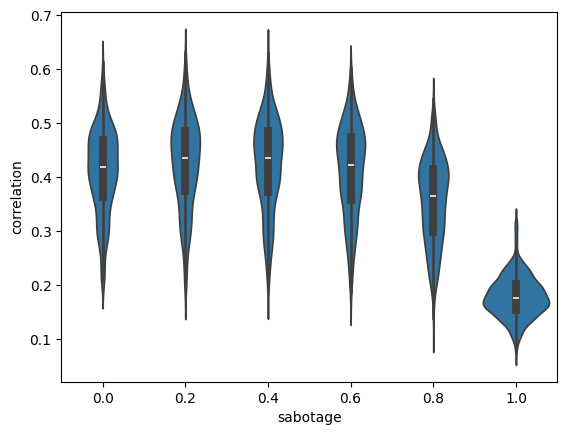

In [4]:
df = sabotage[sabotage["method"]=="cset"]
sns.violinplot(df, x="sabotage", y="correlation")

<Axes: xlabel='sabotage', ylabel='correlation'>

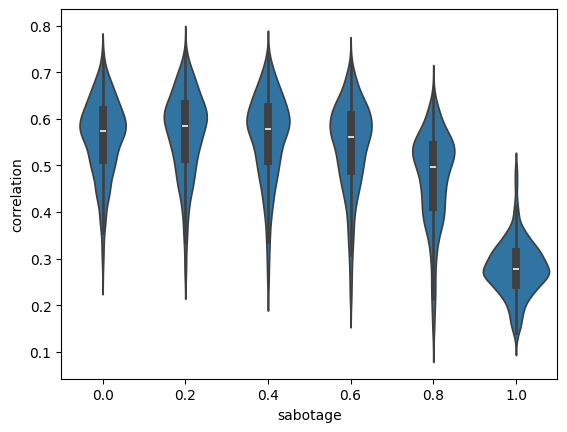

In [5]:
df = sabotage[sabotage["method"]=="wcset"]
sns.violinplot(df, x="sabotage", y="correlation")